# Notebook 05: Interference From Indivisibility

**Goal:** Build a double-slit model as a genuine stochastic process, show that on this model
interference and indivisibility appear together, and see exactly how far that link goes.

By the end of this notebook you will be able to:
- Build the double slit as a unistochastic process on transverse modes
- Test Barandes' divisibility condition on that same model, without matrix inversion
- Show that the fringe pattern *is* the divisibility defect, entry for entry
- Tune the coherence and watch interference and indivisibility vanish together on this model
- Tell *existential* divisibility (some valid middle step exists) from *matched* divisibility
  (the process's own middle step composes), and see a completion where fringes and divisibility coexist

<!-- sources:papers-1-3 -->
**Sources.** "Paper 1, 2, 3" are Jacob A. Barandes's papers:
- Paper 1: "The Stochastic-Quantum Correspondence", arXiv:2302.10778 (*Philosophy of Physics* 3(1), 8, 2025).
- Paper 2: "The Stochastic-Quantum Theorem", arXiv:2309.03085.
- Paper 3: "Quantum Systems as Indivisible Stochastic Processes", arXiv:2507.21192 (*Stud. Hist. Phil. Sci.* 119, 102213, 2026).

Other works are cited in the text by author and arXiv number or journal reference; the full list is in `REFERENCES.md`.

In [1]:
import sys
import os
sys.path.insert(0, os.path.abspath('..'))

%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from isp.divisibility import check_divisibility_lp
from isp.double_slit import (
    double_slit_matrices,
    fringe_visibility,
    make_double_slit_process,
    screen_distribution,
)

## 1. The Double Slit as a Stochastic Process

Three times, one particle, n transverse modes:

    t0  source  --U1-->  t1  slit plane  --U2-->  t2  screen

U1 sends the source into the balanced superposition of the two slits.
U2 is the unitary DFT, which is Fraunhofer (far-field) propagation. Because U2 is
unitary its columns are orthonormal, so the two slit amplitudes do not overlap and
Born-rule probabilities normalise on their own.

The transition matrices are unistochastic, G[i,j] = |U[i,j]|^2:

| matrix | meaning |
|---|---|
| G(t1,t0) = abs(U1)^2 | source to slits |
| G(t2,t1) = abs(U2)^2 | slits to screen |
| G(t2,t0) = abs(U2 U1)^2 | source to screen, coherent |

The decohered alternative, a which-path measurement at the slits, replaces the last one
with the product G(t2,t1) G(t1,t0). Whether those two agree is whether abs(U2)^2 works as
the slit-to-screen step. Divisibility asks the broader question of whether *any* valid
slit-to-screen matrix does (section 3).

In [2]:
m = double_slit_matrices(n_modes=24, slit_a=10, slit_b=13, coherence=1.0)
n, source = m['n_modes'], m['source']
U1, U2 = m['U1'], m['U2']

amp_A, amp_B = U2[:, m['slit_a']], U2[:, m['slit_b']]

print('U1 unitary:', np.allclose(U1.conj().T @ U1, np.eye(n)))
print('U2 unitary:', np.allclose(U2.conj().T @ U2, np.eye(n)))
print()
print('slit amplitudes are complex and orthonormal')
print(f'  <A|A> = {abs(amp_A.conj() @ amp_A):.12f}')
print(f'  <B|B> = {abs(amp_B.conj() @ amp_B):.12f}')
print(f'  <A|B> = {abs(amp_A.conj() @ amp_B):.2e}')
print()
for name in ('gamma_10', 'gamma_21', 'gamma_20_coherent', 'gamma_20_decohered'):
    G = m[name]
    print(f'  {name:20s} columns sum to 1: {np.allclose(G.sum(axis=0), 1)}')

U1 unitary: True
U2 unitary: True

slit amplitudes are complex and orthonormal
  <A|A> = 1.000000000000
  <B|B> = 1.000000000000
  <A|B> = 1.23e-15

  gamma_10             columns sum to 1: True
  gamma_21             columns sum to 1: True
  gamma_20_coherent    columns sum to 1: True
  gamma_20_decohered   columns sum to 1: True


## 2. Interference

The screen distribution for a particle emitted from the source is the source column of
G(t2,t0). Coherent gives amplitudes-then-square; decohered gives probabilities-then-add.

In [3]:
p_quantum = screen_distribution(m, 'gamma_20_coherent')
p_classical = screen_distribution(m, 'gamma_20_decohered')
interference = p_quantum - p_classical

k = np.arange(n)
delta = m['slit_b'] - m['slit_a']
closed_form = (1 + np.cos(2 * np.pi * k * delta / n)) / n

print('no rescaling is applied anywhere')
print(f'  sum p_quantum   = {p_quantum.sum():.15f}')
print(f'  sum p_classical = {p_classical.sum():.15f}')
print()
print(f'interference term sums to {interference.sum():+.2e}')
print('  it redistributes probability, it does not create any')
print()
print(f'p_quantum matches (1 + cos(2 pi k d / n))/n to {np.abs(p_quantum - closed_form).max():.2e}')
print(f'p_classical is exactly flat at 1/n: {np.allclose(p_classical, 1 / n)}')
print()
print(f'fringe visibility, quantum   = {fringe_visibility(p_quantum):.6f}')
print(f'fringe visibility, decohered = {fringe_visibility(p_classical):.2e}')

no rescaling is applied anywhere
  sum p_quantum   = 1.000000000000001
  sum p_classical = 1.000000000000000

interference term sums to +5.00e-16
  it redistributes probability, it does not create any

p_quantum matches (1 + cos(2 pi k d / n))/n to 2.29e-16
p_classical is exactly flat at 1/n: True

fringe visibility, quantum   = 1.000000
fringe visibility, decohered = 2.50e-16


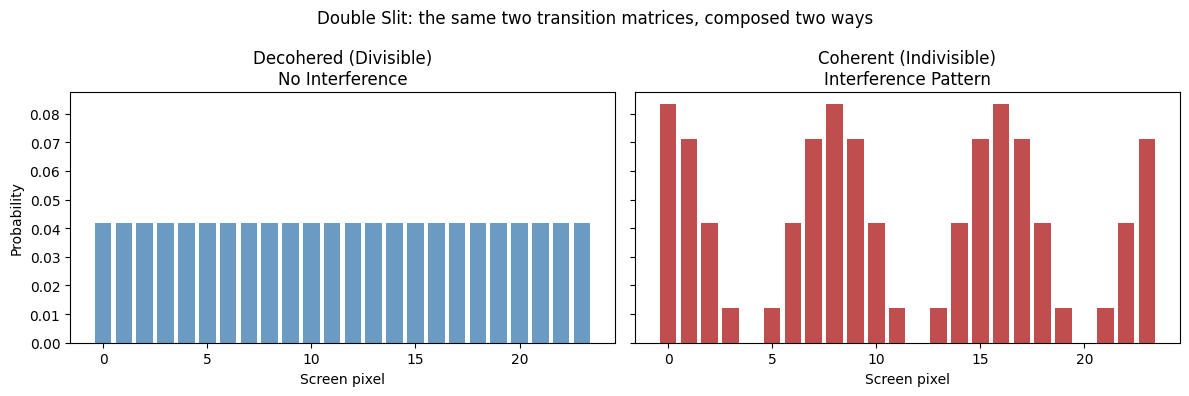

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

ax1.bar(k, p_classical, width=0.8, alpha=0.8, color='steelblue')
ax1.set_title('Decohered (Divisible)\nNo Interference')
ax1.set_xlabel('Screen pixel')
ax1.set_ylabel('Probability')

ax2.bar(k, p_quantum, width=0.8, alpha=0.8, color='firebrick')
ax2.set_title('Coherent (Indivisible)\nInterference Pattern')
ax2.set_xlabel('Screen pixel')

plt.suptitle('Double Slit: the same two transition matrices, composed two ways')
plt.tight_layout()
plt.show()

## 3. Divisibility, Tested on This Model

Notebooks 02 and 03 test divisibility by solving G(t2,t1) = G(t2,t0) inv(G(t1,t0)) and
looking for negative entries. That needs G(t1,t0) to be invertible, and here it never is.

If a unitary sends the source to the balanced superposition of slits A and B, then rows
A and B of U1 each have entry 1/sqrt(2) in the source column. Orthonormality of the rows
forces the Cauchy-Schwarz inequality on the remaining entries to be saturated, so those
row tails must be proportional, which makes rows A and B of abs(U1)^2 *identical*. The
matrix is rank-deficient for every balanced two-slit model. The inverse-based test is
not inconclusive here; it is unavailable.

So test the condition the way Barandes states it: does **any** valid stochastic matrix
G(t2,t1) satisfy G(t2,t0) = G(t2,t1) G(t1,t0)? That is a linear program, and needs no
inverse.
For two configurations, Pimenta (arXiv:2505.08785, §III.1) characterises divisibility geometrically,
singular G(t1,t0) included; the LP handles any number of configurations.

In [5]:
g10 = m['gamma_10']
print('the inverse-based test is structurally unavailable:')
print(f'  rows A and B of abs(U1)^2 identical: {np.allclose(g10[m["slit_a"]], g10[m["slit_b"]])}')
print(f'  rank abs(U1)^2 = {np.linalg.matrix_rank(g10)} of {n}')
print()

for coherence in (1.0, 0.0):
    proc = make_double_slit_process(coherence=coherence)
    result = check_divisibility_lp(proc)
    label = 'coherent' if coherence else 'decohered'
    print(f'{label:10s} (coherence={coherence}):')
    print(f'  divisible    = {result["divisible"]}')
    print(f'  failure_mode = {result["failure_mode"]}')
    print(f'  defect       = {result["defect"]:.6f}')

witness = check_divisibility_lp(make_double_slit_process(coherence=0.0))['witness']
print()
print('the decohered process has a valid intermediate matrix:')
print(f'  non-negative: {witness.min() >= -1e-9}')
print(f'  columns sum to 1: {np.allclose(witness.sum(axis=0), 1)}')
print(f'  and abs(U2)^2 is itself one such solution: '
      f'{np.allclose(m["gamma_21"] @ g10, m["gamma_20_decohered"])}')

the inverse-based test is structurally unavailable:
  rows A and B of abs(U1)^2 identical: True
  rank abs(U1)^2 = 23 of 24

coherent   (coherence=1.0):
  divisible    = False
  failure_mode = no_valid_intermediate_matrix
  defect       = 11.998165
decohered  (coherence=0.0):
  divisible    = True
  failure_mode = None
  defect       = 0.000000

the decohered process has a valid intermediate matrix:
  non-negative: True
  columns sum to 1: True
  and abs(U2)^2 is itself one such solution: True


## 4. The Fringe Pattern *Is* the Divisibility Defect

Define the defect matrix

    D = G(t2,t0) - G(t2,t1) G(t1,t0)

which is zero exactly when the process composes classically through G(t2,t1) = abs(U2)^2.
Its source column is the interference pattern. Not analogous to it, equal to it.

max abs( (p_quantum - p_classical) - D[:, source] ) = 0.00e+00

D[:, source] goes negative at 9 of 24 pixels
  those are the dark fringes
D ranges from -0.041667 to 0.215282


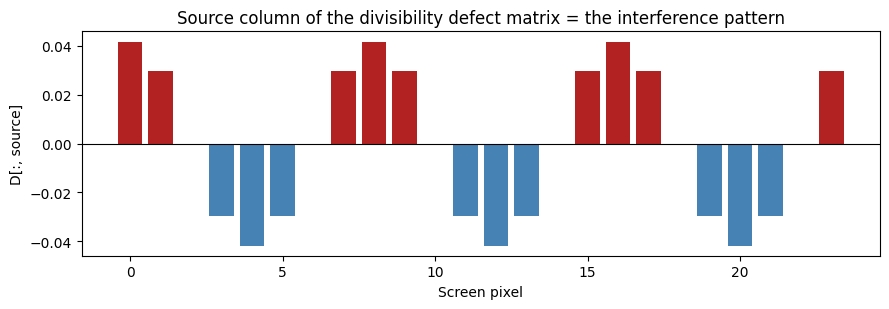

In [6]:
D = m['gamma_20_coherent'] - m['gamma_21'] @ m['gamma_10']

print(f'max abs( (p_quantum - p_classical) - D[:, source] ) = '
      f'{np.abs(interference - D[:, source]).max():.2e}')
print()
print(f'D[:, source] goes negative at {(D[:, source] < -1e-12).sum()} of {n} pixels')
print('  those are the dark fringes')
print(f'D ranges from {D.min():.6f} to {D.max():.6f}')

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(k, D[:, source], width=0.8,
       color=np.where(D[:, source] >= 0, 'firebrick', 'steelblue'))
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xlabel('Screen pixel')
ax.set_ylabel('D[:, source]')
ax.set_title('Source column of the divisibility defect matrix = the interference pattern')
plt.tight_layout()
plt.show()

## 5. Interference and Indivisibility Together, on This Model

Dephasing the slit-plane density matrix by a factor c on its off-diagonal entries and
propagating gives, for every input mode,

    G_c(t2,t0) = (1 - c) G(t2,t1) G(t1,t0)  +  c abs(U2 U1)^2

so c = 1 is a fully coherent particle and c = 0 is a which-path measurement.
Sweep c and measure both quantities on the same process.

In [7]:
coherences = np.linspace(0, 1, 21)
visibility, column_defect, divisible = [], [], []

for c in coherences:
    mc = double_slit_matrices(coherence=c)
    p = screen_distribution(mc)
    visibility.append(fringe_visibility(p))
    column_defect.append(np.abs(p - screen_distribution(mc, 'gamma_20_decohered')).sum())
    divisible.append(check_divisibility_lp(make_double_slit_process(coherence=c))['divisible'])

visibility = np.array(visibility)
column_defect = np.array(column_defect)
divisible = np.array(divisible)

print(f'visibility equals the coherence exactly: max error {np.abs(visibility - coherences).max():.2e}')
print(f'divisible only at c = {coherences[divisible]}')
print(f'interference present wherever indivisible: {np.all(visibility[~divisible] > 1e-12)}')
print(f'no interference wherever divisible:        {np.all(visibility[divisible] < 1e-12)}')

visibility equals the coherence exactly: max error 2.50e-16
divisible only at c = [0.]
interference present wherever indivisible: True
no interference wherever divisible:        True


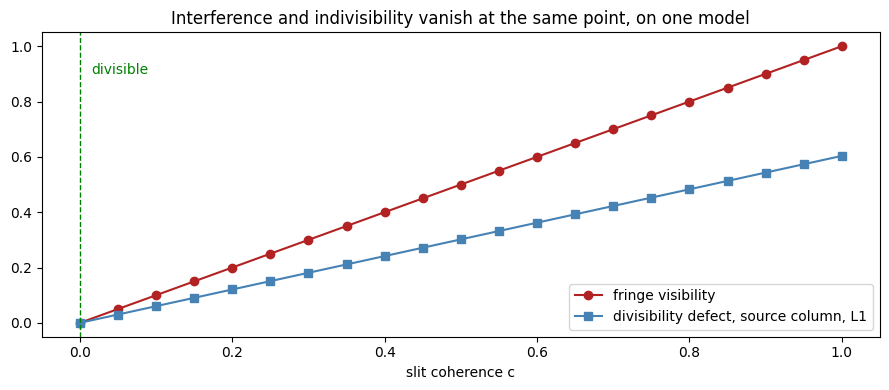

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(coherences, visibility, 'o-', color='firebrick', label='fringe visibility')
ax.plot(coherences, column_defect, 's-', color='steelblue',
        label='divisibility defect, source column, L1')
ax.axvline(0, color='green', linestyle='--', linewidth=1)
ax.annotate('divisible', xy=(0.015, 0.9), color='green')
ax.set_xlabel('slit coherence c')
ax.set_title('Interference and indivisibility vanish at the same point, on one model')
ax.legend()
plt.tight_layout()
plt.show()

## 6. The Prediction Does Not Depend on the Arbitrary Part of the Model

Only the source column of U1 is physical. The remaining columns are an arbitrary
orthonormal completion, needed because a process requires a full transition matrix.
Vary that completion and check that nothing observable moves.

What this does and does not show. The screen distributions use only the physical source column, so they cannot
change. The divisibility verdict uses the whole matrix. The source column on its own can always be matched by a valid
intermediate step: give slits A and B the coherent screen distribution as their columns. So "indivisible" is a statement
about the full process, and here it is confirmed for these five completions, not proved for all of them.
Section 7 shows why that caveat matters.


In [9]:
reference = double_slit_matrices(seed=7)

for seed in (1, 7, 42, 99, 2026):
    ms = double_slit_matrices(seed=seed)
    same = all(np.allclose(screen_distribution(ms, key), screen_distribution(reference, key))
               for key in ('gamma_20_coherent', 'gamma_20_decohered'))
    verdict = check_divisibility_lp(make_double_slit_process(seed=seed))['divisible']
    print(f'seed {seed:5d}: identical screen distributions {same},  divisible {verdict}')

seed     1: identical screen distributions True,  divisible False
seed     7: identical screen distributions True,  divisible False
seed    42: identical screen distributions True,  divisible False
seed    99: identical screen distributions True,  divisible False


seed  2026: identical screen distributions True,  divisible False


## 7. A Completion Where the Two Come Apart

Sections 5 and 6 found interference and indivisibility together for every completion of U1 they
tried. That is a property of those completions, not a law. Two different questions hide in the
word "divisible":

- **Existential divisibility** (Barandes's definition, Paper 1, eq. 6): does *some* valid
  stochastic G(t2,t1) satisfy G(t2,t0) = G(t2,t1) G(t1,t0)? The LP tests this.
- **Matched divisibility**: does the process's *own* slit-to-screen matrix, G(t2,t1) = abs(U2)^2,
  compose with G(t1,t0)? That is D = 0 in section 4. Calvo (arXiv:2601.18720), Fig. 2, and
  Doukas (arXiv:2602.22095), footnote 9, use this notion.

Interference always breaks matched divisibility: the fringes *are* the source column of D. It need
not break existential divisibility. Take n = 8, source 0, slits 3 and 5 (symmetric about the
source on the ring of modes: A + B ≡ 2s mod n), the same DFT second stage, and complete U1 with a
real block on {source, A, B} and the identity elsewhere:

$$U_1\big|_{\{0,3,5\}} = \begin{pmatrix} 0 & 1/\sqrt2 & -1/\sqrt2 \\ 1/\sqrt2 & -1/2 & -1/2 \\ 1/\sqrt2 & 1/2 & 1/2 \end{pmatrix}$$

Its source column is the same balanced slit preparation, so the fringes are the same kind as before.

In [10]:
from isp.double_slit import far_field_propagator
from isp.stochastic import PairwiseProcess

n8, s8, a8, b8 = 8, 0, 3, 5
r = 1 / np.sqrt(2)
block = np.array([[0, r, -r],
                  [r, -0.5, -0.5],
                  [r, 0.5, 0.5]])
U1s = np.eye(n8, dtype=complex)
U1s[np.ix_([s8, a8, b8], [s8, a8, b8])] = block
U2s = far_field_propagator(n8)
g10s, g21s = np.abs(U1s) ** 2, np.abs(U2s) ** 2
print('U1 unitary:', np.allclose(U1s.conj().T @ U1s, np.eye(n8)))
print()

for c in (0.0, 0.25, 0.5, 0.51, 0.75, 1.0):
    g20s = (1 - c) * g21s @ g10s + c * np.abs(U2s @ U1s) ** 2
    proc_s = PairwiseProcess(states=[str(i) for i in range(n8)], times=[0.0, 1.0, 2.0],
                             matrices={(0, 1): g10s, (1, 2): g21s, (0, 2): g20s})
    res = check_divisibility_lp(proc_s)
    print(f'c = {c:4.2f}:  visibility {fringe_visibility(g20s[:, s8]):.2f}   '
          f'existential: divisible {str(res["divisible"]):5s}   '
          f'matched: sum abs(D) = {np.abs(g20s - g21s @ g10s).sum():.2f}')

print()
lab = check_divisibility_lp(make_double_slit_process(coherence=0.01))
print(f'lab completion (n = 24, seed 7) at c = 0.01: divisible {lab["divisible"]}')

U1 unitary: True

c = 0.00:  visibility 0.00   existential: divisible True    matched: sum abs(D) = 0.00
c = 0.25:  visibility 0.25   existential: divisible True    matched: sum abs(D) = 0.25
c = 0.50:  visibility 0.50   existential: divisible True    matched: sum abs(D) = 0.50
c = 0.51:  visibility 0.51   existential: divisible False   matched: sum abs(D) = 0.51
c = 0.75:  visibility 0.75   existential: divisible False   matched: sum abs(D) = 0.75
c = 1.00:  visibility 1.00   existential: divisible False   matched: sum abs(D) = 1.00

lab completion (n = 24, seed 7) at c = 0.01: divisible False


Up to c = 1/2 the fringes are there (visibility c), yet a valid slit-to-screen matrix exists: the
process is divisible in Barandes's sense. It turns indivisible just above c = 1/2. Matched
divisibility fails for every c > 0. The lab's own completion is already indivisible at c = 0.01.

Scanning real completions of this block form at c = 1/4, the symmetric slit pairs (3, 5) and (2, 6)
admit a divisible completion, while the asymmetric pairs tried, (2, 5), (1, 4) and (1, 2), do not.
So, in general, interference does not make a given completion indivisible. What it always does is
break the composition through the process's own G(t2,t1). Which completions admit a stochastic
middle step is not characterised here.

## Summary

| Property | Decohered (c = 0) | Coherent (c > 0) |
|---|---|---|
| Probabilities add | yes | no |
| Amplitudes add | no | yes |
| Interference pattern | no | yes |
| Matched divisible (abs(U2)^2 composes) | yes | no |
| Existential divisible (some valid G(t2,t1)), lab completions | yes | no |
| Fringe visibility | 0 | c |

Every row of that table was computed on the same three matrices, with the lab's completion of U1.
The existential row concerns the full transition matrix, and it depends on the completion: for the
source column alone a valid G(t2,t1) always exists (section 6), and section 7's symmetric
completion stays divisible up to c = 1/2 while showing fringes.

**The interference pattern is the matched-divisibility defect.** G(t2,t0) - G(t2,t1) G(t1,t0)
is not merely correlated with the fringes; its source column equals them exactly. Summing over
which-slit with the process's own slit-to-screen matrix is legitimate only when D = 0, and
interference is what you get when it is not. Whether *some other* valid middle step exists is a
separate question, answered by the LP, and its answer depends on the arbitrary completion.

Prior work: the fringe identity is Paper 1, eq. 43, where Barandes calls interference "a generic
discrepancy" between the indivisible dynamics and a heuristic divisible one (§3.5); he does not
claim that interference occurs if and only if a process is indivisible. See also LeBlond
(arXiv:2511.02863). The existential/matched distinction follows Calvo (arXiv:2601.18720) and
Doukas (arXiv:2602.22095).
